In [2]:
import time
import h5py
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import yaml
from scipy import stats as st

# integrated data imports
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')
from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path


### Load in desired keys for h5 and yaml files
- APD and FIM can use h5 directly
- Transmission and SVLS can use integrating so have energy specification

In [ ]:
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 66
fyaml = '../roi_input.yml'                        

fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5' 

runs_with_andor = [61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]

# extract detector data directly from h5 file
with h5py.File(fname, 'r') as h5:
    g       = h5['intg/axis_svls']
    count   = g['count'][:].squeeze()
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]
    svls_proj = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
    apd_wf = g['det_crix_w8_sum_full_area'][:]
    if run in runs_with_andor:
        andor_full = h5['intg/andor_dir/full_area'][:]

mono_runs=[112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141,143,145]
    
    
# same data, but this is with some processing to have the mono calibration ready
small_data = SmallData(fname, fyaml)
intg_svls = small_data.integrating.svls


with open(fyaml) as f:
    cfg = yaml.safe_load(f)
fim0_cfg = cfg['fim0']
fim1_cfg = cfg['fim1']
apd_cfg = cfg['apd']

### FIM (I0) Integrated Shots

In [4]:
#################################### I_0 from inputs in yaml file ######################
def i0_sum(wf, fim_yaml):
    """
    Determines the FIM/APD intensities (I0) with desired channels and rois from yaml input file
    Utilizes a boolean mask to help choose the paricular channels and roi regions
    """
    wf = np.array(wf)
    
    # extract parameters from yaml file
    ch = fim_yaml['channels']
    sig_roi = fim_yaml['roi']
    bg_roi = fim_yaml['bg_roi']
    
    # select only relevant channels
    wf_ch = wf[:,ch,:]
    
    # determine the background for desired channels
    bg_lo, bg_hi = bg_roi
    base = wf_ch[:,:,bg_lo:bg_hi].mean(axis=-1, keepdims=True)
    
    # subtract baseline (bc means 'baseline corrected')
    wf_bc = np.abs(wf_ch - base)
    
    # creates a mask that gives the desired signal rois for desired channels
    roi_mask = np.zeros(wf_ch.shape, dtype = bool)
    for idx in range(len(ch)):
        lo, hi = sig_roi[idx]
        roi_mask[:,idx,lo:hi] = True
        
    # apply mask to return the signal
    return (wf_bc * roi_mask).sum(axis=(-2, -1))


# array that stores I_0 for all integrated shots
I0_int = i0_sum(fim0_wf, fim0_cfg) + i0_sum(fim1_wf, fim1_cfg)
I0_int = I0_int.flatten()

### SVLS Integrated Shots

In [5]:
# collapsing the "energy axis" to include all features and intensities
svls_int = svls_proj.sum(axis=1)
svls_int = svls_int.flatten()

### APD (TFY) Integrated Shots

In [6]:
apd_wf = np.array(apd_wf)
apd_wf.shape
tfy_int =i0_sum(apd_wf, apd_cfg)
tyf_int = tfy_int.flatten()


### Transmission (Andor) Integrated Shots

In [ ]:
# check which runs have the andor integrated detector
all_runs = list(range(11, 252))

runs_with_andor = []
for run in all_runs:
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5' 
    try:
        with h5py.File(fname, 'r') as f:
            if 'intg' in f:
                if 'andor_dir' in f['intg'].keys():
                    runs_with_andor.append(run) 
    except OSError as e:
        print(f"Skipping Run {run}: {e}")
        continue

print(runs_with_andor)

Skipping Run 32: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Skipping Run 177: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Skipping Run 216: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
[21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]


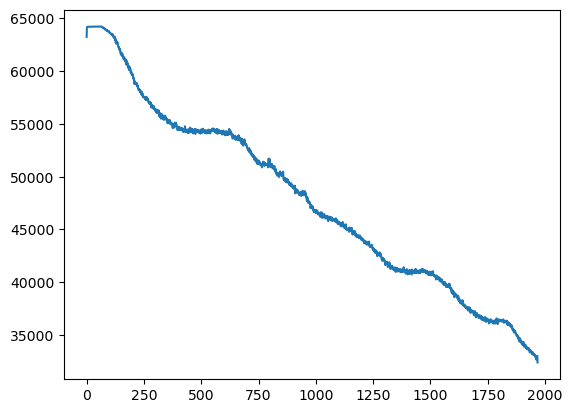

In [7]:

# seems like some detector malfunction in the middle of the spectrum, remove points [800:880]
andor_full_no_noise = np.concatenate((andor_full[:,:800], andor_full[:,880:]), axis=1)

andor_proj = andor_full_no_noise.sum(axis=1)
andor_proj = andor_proj.flatten()

plt.figure()
plt.plot(andor_full_no_noise[5000,:])
plt.show()


### Raw Shot Count Integrated Shots

In [8]:
# ---- count mask: keep frames with the expected number of shots ----
mode_c = st.mode(count, keepdims=False)[0]
count_mask  = (count > mode_c-2) & (count < mode_c+2)

### I0 vs. SVLS
- ideally we want a linear fit
- not sure if this is a good estimate though as each integrated svls shot has inherent difference in signal due to amount of absorption at the particular incident energy
- if I bin by energies, then would I have enough points to still do the linear fit?

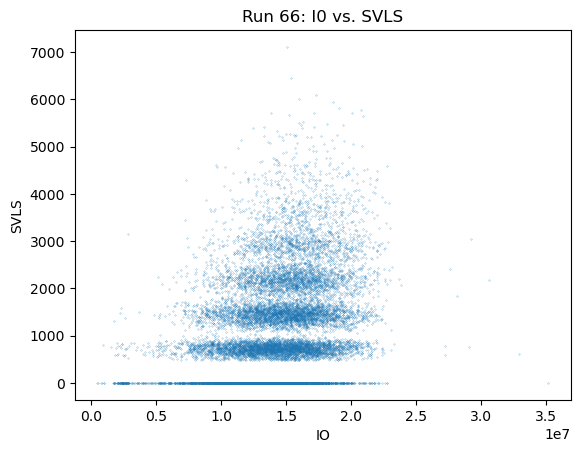

In [9]:
plt.figure()
plt.scatter(I0_int, svls_int, s=0.03)
plt.title(f'Run {run}: I0 vs. SVLS')
plt.xlabel('IO')
plt.ylabel('SVLS')
plt.show()

### I0 vs. TFY
- should have a similar pattern to I0 vs. SVLS?

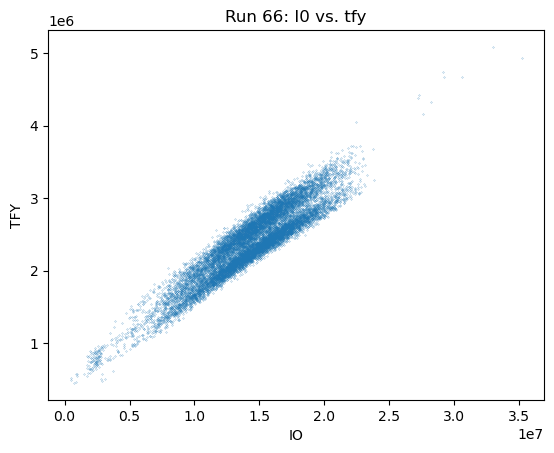

In [10]:
plt.figure()
plt.scatter(I0_int, tfy_int, s=0.03)
plt.title(f'Run {run}: I0 vs. tfy')
plt.xlabel('IO')
plt.ylabel('TFY')
plt.show()

### TFY vs. SVLS
- This should have a linear fit as both are happening after the sample

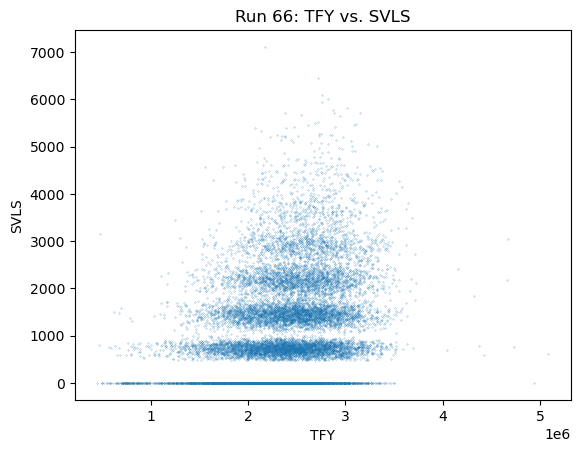

In [11]:
plt.figure()
plt.scatter(tfy_int, svls_int, s=0.03)
plt.title(f'Run {run}: TFY vs. SVLS')
plt.xlabel('TFY')
plt.ylabel('SVLS')
plt.show()

### I0 vs. Transmission
- to be honest, I don't think this data has any meaning lol
- I mean its lowkey linear, probably the best so far lol, but it shouldn't be though lol
    - The signal intensity should change per integrated shot as it is at a different delay

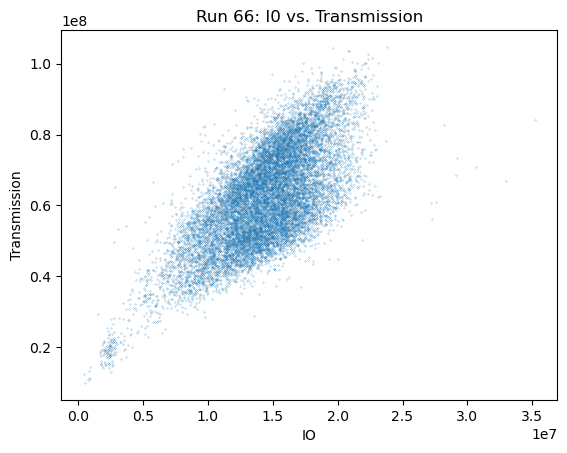

In [12]:
plt.figure()
plt.scatter(I0_int, andor_proj, s=0.03)
plt.title(f'Run {run}: I0 vs. Transmission')
plt.xlabel('IO')
plt.ylabel('Transmission')
plt.show()

In [ ]:
import h5py, numpy as np, matplotlib.pyplot as plt
from chemrixs.utils import get_CIE

base_folder='/sdf/data/lcls/ds/rix/'; exp='rix101231825'
fyaml='../roi_input.yml'; bgyaml='../BGroi_input.yml'

PEAKS = {700.3:(699.8,701.4), 704.4:(703.8,705.3)}   # reference resonances for alignment
COMMON = np.linspace(696.5,710.5,35)                 # match your reduced 35-bin maps


def centroid(x,p,lo,hi):
    m=(x>lo)&(x<hi); return np.nansum(x[m]*p[m])/np.nansum(p[m]) if np.nansum(p[m])>0 else np.nan

def process_set(runs, bgrun, label):
    bgname=f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
    avg = Average(runs, proc_path='proc/Run', avg='mean',
                  output_path=f'avg/{label}.h5',
                  raw_path=f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run',
                  bgpath=bgname, fyaml=fyaml, bgyaml=bgyaml, save=True, norm=True)

    # per-run rigid mono shift from the two reference peaks (OFF spectra)
    shifts={}
    for r in runs:
        with h5py.File(f'proc/Run{r:04d}.h5','r') as f:
            x=np.asarray(f['scanvar_off'][()]).squeeze()
            p=np.nansum(np.asarray(f['axis_svls_off_mean'][()]),1)
        s=[t-centroid(x,p,lo,hi) for t,(lo,hi) in PEAKS.items()]
        shifts[r]=np.nanmean(s)

    def regrid(r,key):
        with h5py.File(f'proc/Run{r:04d}.h5','r') as f:
            xk='scanvar_off' if 'off' in key else 'scanvar_on'
            x=np.asarray(f[xk][()]).squeeze()+shifts[r]; y=np.asarray(f[key][()])
        y2=y[:,None] if y.ndim==1 else y
        out=np.full((len(COMMON),y2.shape[1]),np.nan)
        for j in range(y2.shape[1]):
            out[:,j]=np.interp(COMMON,x,y2[:,j],left=np.nan,right=np.nan)
        return out.squeeze() if y.ndim==1 else out

    keys=['axis_svls_on_mean','axis_svls_off_mean','axis_svls_on_std','axis_svls_off_std']
    acc={}; wsum={'on':np.zeros(len(COMMON)),'off':np.zeros(len(COMMON))}
    for r in runs:
        with h5py.File(f'proc/Run{r:04d}.h5','r') as f:
            co=np.asarray(f['counts_on'][()]).squeeze(); cf=np.asarray(f['counts_off'][()]).squeeze()
            xon=np.asarray(f['scanvar_on'][()]).squeeze()+shifts[r]
            xoff=np.asarray(f['scanvar_off'][()]).squeeze()+shifts[r]
        co_c=np.interp(COMMON,xon,co,left=0,right=0); cf_c=np.interp(COMMON,xoff,cf,left=0,right=0)
        for k in keys:
            lab='on' if 'on' in k else 'off'; m=np.nan_to_num(regrid(r,k),nan=0.0)
            w=(co_c if lab=='on' else cf_c)[:,None]
            if k not in acc: acc[k]=np.zeros_like(m)
            acc[k]+=m*w
        wsum['on']+=co_c; wsum['off']+=cf_c
    for k in keys:
        lab='on' if 'on' in k else 'off'; w=wsum[lab][:,None]
        avg.average[k]=np.divide(acc[k],w,out=np.full_like(acc[k],np.nan),where=w>0)
    avg.average['scanvar_on']=COMMON; avg.average['scanvar_off']=COMMON
    avg.average['counts_on']=wsum['on']; avg.average['counts_off']=wsum['off']

    avg.get_PFYs(); avg.average['E_emi']=avg.get_emi()
    avg.plot_svls2D_ET(figsize=(12,4), mode='mean')   # builds data_trans_off etc.
    plt.close()                                        # suppress the per-set ET figure
    print(f'{label}: shifts(meV)=', {r:round(s*1000) for r,s in shifts.items()})
    return avg

In [ ]:
py_runs    =  [112,114,115,116,117,118,119,120,121,122,123,127,138,139,140,141,142,145]
meopy_runs = [226,227,228,233,234,236,237,238,248,249]

avg_py    = process_set(py_runs,    bgrun=86,  label='py')      # shift3 bg
avg_meopy = process_set(meopy_runs, bgrun=191, label='meopy')   # shift4 bg

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,5), sharex=True)
for a in avg_py, avg_meopy: pass
sets = [('py', avg_py, 'tab:blue'), ('meopy', avg_meopy, 'tab:red')]



for name, A, c in sets:
    x = A.average['scanvar_off']
    ax[0].plot(x, A.average['PFY_off_mean'], c, label=f'{name} off')
    ax[0].fill_between(x, A.average['PFY_off_mean']-A.average['PFY_off_std'],
                          A.average['PFY_off_mean']+A.average['PFY_off_std'], color=c, alpha=.2)
    ax[1].plot(x, A.average['PFY_on_mean']-A.average['PFY_off_mean'], c, label=f'{name} on-off')
ax[1].axhline(0, ls='--', c='gray')
ax[0].set_title('PFY (off) — ground state'); ax[1].set_title('PFY (on − off) — transient')
for a in ax: a.set_xlabel('incident energy (eV)'); a.legend()
ax[0].set_ylabel('PFY'); plt.tight_layout(); plt.show()

In [ ]:
E_CIE = 706.7; WIDTH = 3
NORM  = 'peak'        # 'area' (integral=1), 'peak' (max=1), or 'none'

fig, ax = plt.subplots(figsize=(9,5))
for name, A, c in sets:
    CIE_off, CIE_off_std = get_CIE(E_CIE, WIDTH,
                                   A.average['mono_off'],
                                   A.average['data_trans_off'],
                                   A.average['std_trans_off'])
    ET = A.average['E_trans_off'] - 0.2
    if name == 'meopy':
        ET = ET + 0.2

    if NORM == 'area':
        f = np.nansum(CIE_off)                     # divide by integral
    elif NORM == 'peak':
        f = np.nanmax(CIE_off)                     # divide by peak
    else:
        f = 1.0
    y, yerr = CIE_off / f, CIE_off_std / f         # scale error by the SAME factor

    ax.errorbar(ET, y, yerr=yerr, fmt='o-', color=c, ecolor=c,
                elinewidth=0.8, capsize=2, markersize=3, label=f'{name} off')

ax.axhline(0, ls='--', c='gray', lw=0.8)
ax.set_xlabel('energy transfer (eV)')
ax.set_ylabel('normalized intensity' if NORM!='none' else 'intensity (arb. u.)')
ax.set_title(f'CIE (off), E_inc = {E_CIE:.1f} eV, width = {WIDTH} bins  [{NORM}-norm]')
ax.legend(); plt

In [ ]:
import h5py, numpy as np, matplotlib.pyplot as plt
base_folder='/sdf/data/lcls/ds/rix/'; exp='rix101231825'
fyaml='../roi_input.yml'; bgyaml='../BGroi_input.yml'

def mono_off_cie(runs, bgrun, label, halfband=2):
    bgname=f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
    avg = Average(runs, proc_path='proc/Run', avg='mean',
                  output_path=f'avg/{label}_cie.h5',
                  raw_path=f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run',
                  bgpath=bgname, fyaml=fyaml, bgyaml=bgyaml,
                  save=True, norm=True)                 # NO scantype override -> mono fly

    cf = avg.average['counts_off']
    k  = int(np.nanargmax(cf))                          # populated incident-energy bin
    band = slice(max(0,k-halfband), k+halfband+1)
    E_inc = avg.average['scanvar_off'][k]
    print(f'{label}: bin {k}, E_inc={E_inc:.2f} eV, '
          f'neighbors {cf[max(0,k-halfband):k+halfband+1].astype(int)}')

    wf  = cf[band][:, None]
    off = np.nansum(avg.average['axis_svls_off_mean'][band]*wf, 0)/np.nansum(wf)
    off_std = np.sqrt(np.nansum((avg.average['axis_svls_off_std'][band]*wf)**2,0))/np.nansum(wf)

    emi = avg.get_emi()
    ET  = E_inc - emi
    return ET, off, off_std, E_inc

In [ ]:
ET_py,    off_py,    py_std,    Epy    = mono_off_cie([130,131,132,133,134,135,136],
                                                      bgrun=86,  label='py')
ET_meopy, off_meopy, meopy_std, Emeopy = mono_off_cie([241,242,243,244,245,246,247,253],
                                                      bgrun=191, label='meopy')

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
for name, ET, y, yerr, c in [('py',    ET_py,    off_py,    py_std,    'tab:blue'),
                             ('meopy', ET_meopy, off_meopy, meopy_std, 'tab:red')]:
    f = np.nanmax(y)                                   # peak-normalize each set
    if name == 'meopy':
        ET = ET + 0.6
    ax.errorbar(ET-0.4, y/f, yerr=yerr/f, fmt='o-', color=c, ecolor=c,
                elinewidth=0.8, capsize=2, markersize=3, label=f'{name} off')
ax.axhline(0, ls='--', c='gray', lw=0.8)
ax.set_xlabel('energy transfer (eV)'); ax.set_ylabel('normalized intensity')
ax.set_title(f'CIE (off) — py (E={Epy:.1f}) vs meopy (E={Emeopy:.1f}) [peak-norm]')
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def two_gauss(x, A1, m1, s1, A2, m2, s2, C):
    return (A1*np.exp(-(x-m1)**2/(2*s1**2)) +
            A2*np.exp(-(x-m2)**2/(2*s2**2)) + C)

def fit_two_gauss(ET, y, yerr, window=(-1.5, 2.3), p0=None, c='tab:blue', name=''):
    # restrict to the region around 0
    m = (ET > window[0]) & (ET < window[1]) & np.isfinite(y)
    x, yy = ET[m], y[m]
    ee = yerr[m] if yerr is not None else None
    # peak-normalize for stable fitting
    f = np.nanmax(yy); yn = yy/f
    en = ee/f if ee is not None else None

    if p0 is None:                              # data-driven seed: one peak at 0, one offset
        p0 = [1.0, 0.0, 0.3,  0.4, 0.6, 0.4, 0.0]
    # bounds keep widths positive and centers inside the window
    lb = [0,   window[0], 0.05, 0,   window[0], 0.05, -0.5]
    ub = [5,   window[1], 1.5,  5,   window[1], 0.5, 0.5]

    try:
        popt, pcov = curve_fit(two_gauss, x, yn, p0=p0, bounds=(lb, ub),
                               sigma=en, absolute_sigma=(en is not None), maxfev=20000)
        perr = np.sqrt(np.diag(pcov))
    except Exception as e:
        print(f'{name}: fit failed -> {e}'); return None

    xf = np.linspace(window[0], window[1], 400)
    A1,m1,s1,A2,m2,s2,C = popt
    print(f'{name}:  G1 cen={m1:+.3f}±{perr[1]:.3f} eV  FWHM={2.355*s1:.3f}  A={A1*f:.3g}')
    print(f'{name}:  G2 cen={m2:+.3f}±{perr[4]:.3f} eV  FWHM={2.355*s2:.3f}  A={A2*f:.3g}')

    ax.errorbar(x, yn, yerr=en, fmt='o', color=c, ms=3, elinewidth=.7, capsize=2,
                alpha=.6, label=f'{name} data')
    ax.plot(xf, two_gauss(xf, *popt), '-', color=c, lw=1.8, label=f'{name} fit')
    # individual components (dashed)
    ax.plot(xf, A1*np.exp(-(xf-m1)**2/(2*s1**2))+C, '--', color=c, lw=.9, alpha=.7)
    ax.plot(xf, A2*np.exp(-(xf-m2)**2/(2*s2**2))+C, ':',  color=c, lw=.9, alpha=.7)
    return popt, perr

fig, ax = plt.subplots(figsize=(10,6))
fit_two_gauss(ET_py-.35,    off_py,    py_std,    name='py',    c='tab:blue')
# fit_two_gauss(ET_meopy, off_meopy, meopy_std, name='meopy', c='tab:red')
# ax.axvline(0, ls='--', c='gray', lw=.8)
ax.set_xlabel('energy transfer (eV)'); ax.set_ylabel('normalized intensity')
ax.set_title('Two-Gaussian fit around ET = 0'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
import h5py
import numpy as np
import yaml
import matplotlib.pyplot as plt

# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 140
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
# fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
fname = f'{base}/{exp}/hdf5/smalldata/run140_th100_tha480/{exp}_Run{run:04d}.h5' 

fname_dr   = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'          # original
fname_raw  = f'{base}/{exp}/hdf5/smalldata/run140_th100_tha480/{exp}_Run{run:04d}.h5'           # no droplet

with h5py.File(fname_dr, 'r') as h5:
    proj_dr = h5['intg/axis_svls/droplet_dense_curve_corr_pj_ax_1_data'][:]
with h5py.File(fname_raw, 'r') as h5:
    proj_nd = h5['intg/axis_svls/curve_corr_pj_ax_1_data'][:]          # adjust key from h5ls
    # proj_nd = h5['intg/axis_svls/droplet_dense_curve_corr_pj_ax_1_data'][:]
svls_sum_dr = proj_dr.sum(axis=1)
svls_sum_nd = proj_nd.sum(axis=1)




with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']

print(fname)


with h5py.File(fname, 'r') as h5:
    print(h5['Sums'].keys())
    print(h5['intg'].keys())
    fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]   # (shots, channels, samples)
    fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
    print(f'fim0 shape: {fim0_wf.shape}, fim1 shape: {fim1_wf.shape}')


with h5py.File(fname_dr, 'r') as h5:
    g       = h5['intg/axis_svls']
    count   = g['count'][:].squeeze()
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]
    try:
        ek, ea = cfg['epics']['key'], cfg['epics']['attr']['MONO_premirror_pitch']
        premirror = get_premirror_pitch(h5[f'/{ek}/{ea}'][:, 1])
    except Exception:
        premirror = 144506

# ---- count mask: keep frames with the expected number of shots ----
mode_c = st.mode(count, keepdims=False)[0]
cmask  = (count > mode_c-1) & (count < mode_c+1)

# ---- I0 from FIM0 + FIM1, channels 1-4, sig [65:75], bg [0:60] ----
def i0_sum(wf, sig=slice(65, 75), bg=slice(0, 60), channels=(0, 1, 2, 3)):
    ch  = list(channels)
    base = wf[:, ch, bg].mean(axis=-1, keepdims=True)
    return np.abs(wf[:, ch, sig] - base).sum(axis=(-2, -1))

I0_i = i0_sum(fim0_wf) + i0_sum(fim1_wf)

# ---- per-shot mono energy ----
mc = next((np.asarray(r)[2:4] for r in cfg['mono_calib'] if run > r[0] and run < r[1]), None)
assert mc is not None, f'no mono_calib row matches run {run}'
energy_eV = mono_energy(np.polyval(mc, monoenc/count), premirror, fname='../mono_calib.yml')

print(f'{len(count)} shots, mode count = {mode_c}, '
      f'kept by cmask: {cmask.sum()} ({100*cmask.mean():.1f}%)')
print(f'I0: median = {np.median(I0_i):.2e}, range = [{I0_i.min():.2e}, {I0_i.max():.2e}]')
print(f'energy: range = [{np.nanmin(energy_eV):.2f}, {np.nanmax(energy_eV):.2f}] eV')


# # --- plot: mean ± std per channel, with bg_roi (gray) + signal ROI (red) overlaid ---
# fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True)
# nsamp = fim0_wf.shape[-1]; x = np.arange(nsamp)
# rng = np.random.default_rng(0)

# for det_name, wf, det_cfg, axrow in [('fim0', fim0_wf, fim0_cfg, axes[0]),
#                                       ('fim1', fim1_wf, fim1_cfg, axes[1])]:
#     channels, roi, bg_roi = det_cfg['channels'], det_cfg['roi'], det_cfg['bg_roi']
#     for i, c in enumerate(channels):
#         ax = axrow[i]; ch = c - 1   # yaml is 1-indexed
#         m  = wf[:, ch, :].mean(0); s = wf[:, ch, :].std(0)
#         # individual shots (faint)
#         for j in rng.choice(wf.shape[0], 30, replace=False):
#             ax.plot(x, wf[j, ch, :], color='steelblue', alpha=0.1, lw=0.5)
#         ax.plot(x, m, 'k', lw=1.3, label='mean')
#         # ax.fill_between(x, m-s, m+s, color='k', alpha=0.15, label='±1σ')
#         ax.axvspan(bg_roi[0], bg_roi[1], color='gray', alpha=0.25, label='bg_roi')
#         ax.axvspan(roi[i][0], roi[i][1], color='red',  alpha=0.20, label='signal ROI')
#         ax.set_title(f'{det_name} ch{c} (idx {ch})'); ax.set_xlabel('sample')
#         if i == 0: ax.legend(fontsize=8, loc='best')
# plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Assumes you already have in scope from the dropletted SMD:
#   energy_eV, I0_i, cmask   — per-shot, same length as svls_sum_dr / svls_sum_nd
# and from above:
#   svls_sum_dr, svls_sum_nd

# Quick sanity check
assert len(svls_sum_dr) == len(svls_sum_nd) == len(energy_eV), (
    f'shot count mismatch: dr={len(svls_sum_dr)}, nd={len(svls_sum_nd)}, E={len(energy_eV)}'
)
print(f'shots: {len(svls_sum_dr)}  (matches across both files)')
print(f'mean SVLS — dropletted: {svls_sum_dr.mean():.3g}, no droplet: {svls_sum_nd.mean():.3g}, '
      f'ratio nd/dr: {svls_sum_nd.mean()/svls_sum_dr.mean():.2f}')

# ============================================================
#  CHOOSE THE ENERGY TO INSPECT
# ============================================================
E_focus = 700
E_width = 1.0
# ============================================================

m = cmask & (energy_eV >= E_focus - E_width/2) & (energy_eV < E_focus + E_width/2)
n_focus = int(m.sum())
print(f'\n{n_focus} shots in {E_focus:.2f} ± {E_width/2:.2f} eV window')

if n_focus < 10:
    print('⚠ too few shots — widen E_width or pick a different E_focus')
else:
    I0 = I0_i[m]
    SV_dr, SV_nd = svls_sum_dr[m], svls_sum_nd[m]

    # ---- side-by-side scatter at the focus energy ----
    fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True)
    for axx, SV, label, dot_color in [
        (ax[0], SV_dr, 'dropletted (production)', 'tab:blue'),
        (ax[1], SV_nd, 'no droplet',              'tab:orange'),
    ]:
        s, b = np.polyfit(I0, SV, 1)
        r    = np.corrcoef(I0, SV)[0, 1]
        axx.plot(I0, SV, '.', ms=4, alpha=0.35, color=dot_color)
        xx = np.linspace(0, I0.max(), 100)
        # axx.plot(xx, s*xx + b, 'r-',  lw=1.5, label=f'fit: {s:.3g}·I0 + {b:.3g}\nr = {r:.3f}')
        # axx.plot(xx, s*xx,     'g--', lw=1.2, alpha=0.7, label='through origin')
        axx.set_xlim(0); axx.set_ylim(bottom=0)
        axx.set_xlabel('I0'); axx.set_ylabel('SVLS sum')
        axx.set_title(f'{label}\n{E_focus:.1f} ± {E_width/2:.2f} eV  ({n_focus} shots)')
        axx.legend(fontsize=9, loc='upper left')
    plt.tight_layout(); plt.show()

# ============================================================
#  Per-bin r and slope across the full scan, so the focus window
#  isn't judged in isolation
# ============================================================
def per_bin(E, I0, SV, mask, ebin_width=1.0, min_n=10):
    E, I0, SV = E[mask], I0[mask], SV[mask]
    ebins = np.arange(np.floor(np.nanmin(E)), np.ceil(np.nanmax(E)) + 1, ebin_width)
    ecen  = 0.5 * (ebins[:-1] + ebins[1:])
    idx   = np.digitize(E, ebins)
    n     = np.array([(idx == i+1).sum() for i in range(len(ecen))])
    r     = np.full(len(ecen), np.nan)
    slope = np.full(len(ecen), np.nan)
    for i in range(len(ecen)):
        msk = idx == i+1
        if msk.sum() >= min_n:
            slope[i], _ = np.polyfit(I0[msk], SV[msk], 1)
            r[i] = np.corrcoef(I0[msk], SV[msk])[0, 1]
    return ecen, n, r, slope

ecen_dr, n_dr, r_dr, sl_dr = per_bin(energy_eV, I0_i, svls_sum_dr, cmask)
ecen_nd, n_nd, r_nd, sl_nd = per_bin(energy_eV, I0_i, svls_sum_nd, cmask)

# fig, ax2 = plt.subplots(1, 2, figsize=(10, 5))

# ax2[0].plot(ecen_dr, r_dr, 'o-', label='dropletted', color='tab:blue')
# ax2[0].plot(ecen_nd, r_nd, 's-', label='no droplet', color='tab:orange', alpha=0.8)
# # ax2[0].axhline(0.9, ls='--', color='r',    alpha=0.4)
# # ax2[0].axhline(0,   ls=':',  color='gray', alpha=0.5)
# ax2[0].axvspan(E_focus - E_width/2, E_focus + E_width/2, alpha=0.15, color='tab:gray',
#                label=f'focus ({E_focus:.1f} eV)')
# ax2[0].set_ylim(-0.5, 1)
# ax2[0].set_xlabel('energy (eV)'); ax2[0].set_ylabel('Pearson r (SVLS vs I0)')
# ax2[0].set_title('per-bin linearity'); ax2[0].legend(fontsize=9)

# ax2[1].plot(ecen_dr, sl_dr/np.nanmean(sl_dr), 'o-', label='dropletted', color='tab:blue')
# ax2[1].plot(ecen_nd, sl_nd/np.nanmean(sl_nd), 's-', label='no droplet', color='tab:orange', alpha=0.8)
# ax2[1].axvspan(E_focus - E_width/2, E_focus + E_width/2, alpha=0.15, color='tab:gray')
# ax2[1].set_xlabel('energy (eV)'); ax2[1].set_ylabel('slope / mean(slope)')
# ax2[1].set_title('per-bin normalized slope'); ax2[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

In [ ]:
import re

variant_tags = ['th60_tha455',  'th60_tha440',
                'th70_tha455',  'th70_tha440',
                'th80_tha455',  'th80_tha440',
                'th100_tha455', 'th100_tha440']

E_focus = 704.5
E_width = 1.0

m  = cmask & (energy_eV >= E_focus - E_width/2) & (energy_eV < E_focus + E_width/2)
I0 = I0_i[m]
n_focus = int(m.sum())
print(f'{n_focus} shots in {E_focus:.2f} ± {E_width/2:.2f} eV')

def load_sum(fname, key='droplet_dense_curve_corr_pj_ax_1_data'):
    with h5py.File(fname, 'r') as h5:
        return h5[f'intg/axis_svls/{key}'][:].sum(axis=1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True)
axes = axes.ravel()

for i, tag in enumerate(variant_tags):
    path = f'{base}/{exp}/hdf5/smalldata/run{run}_{tag}/{exp}_Run{run:04d}.h5'
    try:
        SV_all = load_sum(path)
    except Exception as e:
        axes[i].set_title(f'{tag}\n(load failed: {e})', fontsize=10)
        continue
    if len(SV_all) != len(I0_i):
        axes[i].set_title(f'{tag}\nshot mismatch ({len(SV_all)} vs {len(I0_i)})', fontsize=10)
        continue

    SV = SV_all[m]
    s, b = np.polyfit(I0, SV, 1)
    r    = np.corrcoef(I0, SV)[0, 1]

    axes[i].plot(I0, SV, '.', ms=4, alpha=0.35, color='tab:blue')
    xx = np.linspace(0, I0.max(), 100)
    # axes[i].plot(xx, s*xx + b, 'r-', lw=1.5)
    axes[i].set_xlim(0); axes[i].set_ylim(bottom=0)
    axes[i].set_xlabel('I0'); axes[i].set_ylabel('SVLS sum')
    axes[i].set_title(f'{tag}\n', fontsize=10)

plt.suptitle(f'SVLS vs I0  @  {E_focus:.1f} ± {E_width/2:.2f} eV  ({n_focus} shots)',
             fontsize=13, y=1.005)
plt.tight_layout(); plt.show()

In [ ]:
E_focus = 705.0
E_width = 1.0

m  = cmask & (energy_eV >= E_focus - E_width/2) & (energy_eV < E_focus + E_width/2)
SV = svls_sum_dr[m]      # production dropletted, this is where peaks should be cleanest

PEAK_1PH = 800           # ADU per photon (from your prior validation: 1γ peak ~800)

fig, ax = plt.subplots(figsize=(12, 5))

# Fine bins to resolve the peaks (~10× narrower than peak separation)
bins = np.arange(0, np.nanpercentile(SV, 99.5) + 75, 75)
counts, edges, _ = ax.hist(SV, bins=bins, color='tab:blue', alpha=0.7,
                            edgecolor='k', linewidth=0.3)

# Mark expected N-photon positions
ymax = counts.max() * 1.08
for n in range(0, int(edges[-1] / PEAK_1PH) + 1):
    ax.axvline(n * PEAK_1PH, ls='--', color='red', alpha=0.55, lw=1)
    ax.text(n * PEAK_1PH, ymax * 0.97, f'{n}γ',
            ha='center', va='top', color='red', fontsize=10, weight='bold')

ax.set_ylim(0, ymax)
ax.set_xlabel('SVLS sum per shot (ADU)')
ax.set_ylabel('shots')
ax.set_title(f'Photon-counting histogram, production dropletting  @  '
             f'{E_focus:.1f} ± {E_width/2:.2f} eV   ({len(SV)} shots)')
plt.tight_layout(); plt.show()

# Quick Poisson-mean estimate from band populations
print(f'shots in 0γ band ([0, {PEAK_1PH//2}]):       '
      f'{((SV >= 0)         & (SV < PEAK_1PH * 0.5 )).sum()}')
for n in range(1, 6):
    lo, hi = (n - 0.5) * PEAK_1PH, (n + 0.5) * PEAK_1PH
    print(f'shots in {n}γ band ([{int(lo)}, {int(hi)}]):  '
          f'{((SV >= lo) & (SV < hi)).sum()}')
print(f'shots above 5γ:                  {(SV >= 5.5 * PEAK_1PH).sum()}')
print(f'mean SVLS sum:                   {SV.mean():.1f}  '
      f'→  λ ≈ {SV.mean()/PEAK_1PH:.2f} photons/shot')

In [ ]:
def bin_three_ways(E, I0, SV, mask, ebin_width=1.0, min_n=5):
    E, I0, SV = E[mask], I0[mask], SV[mask]
    ebins = np.arange(np.floor(np.nanmin(E)), np.ceil(np.nanmax(E)) + 1, ebin_width)
    ecen  = 0.5 * (ebins[:-1] + ebins[1:])
    idx   = np.digitize(E, ebins)

    mor_mean   = np.full(len(ecen), np.nan)   # mean of ratios: mean(SV/I0)
    mor_sem    = np.full(len(ecen), np.nan)
    ros_mean   = np.full(len(ecen), np.nan)   # ratio of sums: sum(SV)/sum(I0)
    ros_sem    = np.full(len(ecen), np.nan)
    rom_mean   = np.full(len(ecen), np.nan)   # ratio of means: mean(SV)/mean(I0)
    n          = np.zeros(len(ecen), int)

    norm = SV / I0
    for i in range(len(ecen)):
        m = idx == i+1
        if m.sum() >= min_n:
            n[i] = m.sum()
            mor_mean[i] = np.mean(norm[m])
            mor_sem[i]  = np.std(norm[m]) / np.sqrt(n[i])

            ssv, si0 = SV[m].sum(), I0[m].sum()
            ros_mean[i] = ssv / si0
            ros_sem[i]  = np.sqrt(ssv) / si0           # Poisson on numerator

            rom_mean[i] = SV[m].mean() / I0[m].mean()
    return ecen, n, mor_mean, mor_sem, ros_mean, ros_sem, rom_mean

ecen, n, mor_m, mor_e, ros_m, ros_e, rom_m = bin_three_ways(
    energy_eV, I0_i, svls_sum_dr, cmask, ebin_width=0.3)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
# absolute curves
ax[0].errorbar(ecen, mor_m, yerr=mor_e, fmt='o-', label='mean(SV/I0)  [current pipeline]', alpha=0.85)
ax[0].errorbar(ecen, ros_m, yerr=ros_e, fmt='s-', label='sum(SV)/sum(I0)  [Poisson MLE]', alpha=0.85)
ax[0].plot(ecen, rom_m, '^-', label='mean(SV)/mean(I0)  [reference]', alpha=0.7)
ax[0].set_xlabel('energy (eV)'); ax[0].set_ylabel('SVLS / I0')
ax[0].set_title('three normalizations'); ax[0].legend(fontsize=9)

# ratio of error bars (how much noise reduction the MLE gives you)
ax[1].plot(ecen, mor_e / ros_e, 'o-')
ax[1].axhline(1, ls=':', color='gray')
ax[1].set_xlabel('energy (eV)')
ax[1].set_ylabel('σ(mean of ratios) / σ(ratio of sums)')
ax[1].set_title('noise-reduction factor from switching estimator')
plt.tight_layout(); plt.show()

check andor_dir

In [ ]:
import h5py
import numpy as np
import yaml
# import matplotlib.pyplot as plt

# --- config (same header) ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 140
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'   # standard smd file

# fzp_piranha is new -> not in the yaml yet. Set these once you see where the beam sits.
roi        = None        # e.g. [start, stop] over the dispersed transmitted beam
offset_roi = None        # e.g. [start, stop] on flat dark, off the beam
print(fname)

with h5py.File(fname, 'r') as h5:
    g = h5['intg']['axis_svls']
    print('piranha-ish keys:', [k for k in g.keys() if 'piranha' in k.lower()])
    fzp = g['fzp_piranha_sum_full_area'][:].astype(float)     # (frames, pixels), summed over the window
    evc = g['timing_sum_eventcodes'][:]
    cnt = g['count'][:].astype(float)
print(f'fzp_piranha shape: {fzp.shape}')

# laser on/off split (same rule as the proc code)
exp_cnt = np.bincount(cnt.astype(int)).argmax()
on  = (evc[:, 273] / exp_cnt) > 0.5
off = (evc[:, 272] / exp_cnt) > 0.5
print(f'on frames: {on.sum()}   off frames: {off.sum()}')

if fzp.ndim == 2:                                   # line camera -> (frames, dispersion)
    spec     = np.nanmean(fzp, 0)
    spec_on  = np.nanmean(fzp[on],  0) if on.any()  else None
    spec_off = np.nanmean(fzp[off], 0) if off.any() else None
    x = np.arange(spec.size)

    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    for a in ax:
        if spec_off is not None: a.plot(x, spec_off, color='tab:blue',   lw=0.6, alpha=0.7, label='off')
        if spec_on  is not None: a.plot(x, spec_on,  color='tab:orange', lw=0.6, alpha=0.7, label='on')
        a.plot(x, spec, 'k', lw=0.9, label='mean (all)')
        if roi        is not None: a.axvspan(roi[0], roi[1],               color='red',  alpha=0.15, label=f'roi {roi}')
        if offset_roi is not None: a.axvspan(offset_roi[0], offset_roi[1], color='gray', alpha=0.4,  label=f'offset_roi {offset_roi}')
        a.set_ylabel('mean ADU')
    ax[0].legend(fontsize=8); ax[0].set_title(f'fzp_piranha (transmission) — Run {run}')
    ax[1].set_yscale('log'); ax[1].set_xlabel('dispersion pixel'); ax[1].set_title('log scale')
    plt.tight_layout(); plt.show()

    if roi is not None:
        print(f'signal inside roi  : {100*spec[roi[0]:roi[1]].sum()/spec.sum():.2f}%')
    if offset_roi is not None:
        print(f'mean in offset_roi : {spec[offset_roi[0]:offset_roi[1]].mean():.4g}   (pedestal you subtract)')
else:
    print(f'unexpected ndim={fzp.ndim}; piranha should be a 1-D line camera -> (frames, pixels). Inspect before trusting.')

In [ ]:
ped     = np.median(spec)                      # camera pedestal (~7000)
sig     = spec - ped
peak_px = sig.argmax()
above   = np.where(sig > 0.05 * sig.max())[0]  # beam = >5% of peak height above pedestal
lo, hi  = above.min(), above.max()
print(f'pedestal ~{ped:.0f} ADU,  peak at pixel {peak_px},  beam spans [{lo}, {hi}]')
print(f'suggested roi: [{lo-10}, {hi+10}]')

In [ ]:
%history -g